In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# EDA

## HIPÓTESIS

1) ¿Cómo se distribuye la supervivencia?
2) ¿Qué variables parecen influir más?
3) ¿Existen outliers?
4) ¿Hay variables redundantes?
5) Transformaciones para Machine Learning

In [2]:
archivo = './data/Breast_Cancer.csv'
df = pd.read_csv(archivo)
df.head()

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Age                     4024 non-null   int64
 1   Race                    4024 non-null   str  
 2   Marital Status          4024 non-null   str  
 3   T Stage                 4024 non-null   str  
 4   N Stage                 4024 non-null   str  
 5   6th Stage               4024 non-null   str  
 6   differentiate           4024 non-null   str  
 7   Grade                   4024 non-null   str  
 8   A Stage                 4024 non-null   str  
 9   Tumor Size              4024 non-null   int64
 10  Estrogen Status         4024 non-null   str  
 11  Progesterone Status     4024 non-null   str  
 12  Regional Node Examined  4024 non-null   int64
 13  Reginol Node Positive   4024 non-null   int64
 14  Survival Months         4024 non-null   int64
 15  Status                  4024 non

In [9]:
df.describe(include='object')

C:\Users\bgran\AppData\Local\Temp\ipykernel_15896\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Estrogen Status,Progesterone Status,Status
count,4024,4024,4024,4024,4024,4024,4024,4024,4024,4024,4024
unique,3,5,4,3,5,4,4,2,2,2,2
top,White,Married,T2,N1,IIA,Moderately differentiated,2,Regional,Positive,Positive,Alive
freq,3413,2643,1786,2732,1305,2351,2351,3932,3755,3326,3408


In [13]:
df.isnull().sum() # verificamos que no hay valores nulos

Age                       0
Race                      0
Marital Status            0
T Stage                   0
N Stage                   0
6th Stage                 0
differentiate             0
Grade                     0
A Stage                   0
Tumor Size                0
Estrogen Status           0
Progesterone Status       0
Regional Node Examined    0
Reginol Node Positive     0
Survival Months           0
Status                    0
dtype: int64

In [15]:
df.duplicated().sum() # verificamos que no hay valores duplicados

np.int64(1)

Aparece un valor duplicado. Análisis, son datos anonimizados, y dos pacientes pueden tener los mismos datos según esta clasificación por lo que no se puede eliminar

In [16]:
# Nuestra variable objetivo es Survival Months

df['Survival Months'].describe()

count    4024.000000
mean       71.297962
std        22.921430
min         1.000000
25%        56.000000
50%        73.000000
75%        90.000000
max       107.000000
Name: Survival Months, dtype: float64

Tenemos un tamaño muestral de 4024 pacientes, en los que la media de supervivencia es de 71.3 meses. La desviación estándard es bastante grande, 22.9 meses, dejando el rango de supervivencia medio entre 48.4 meses y 94.2 meses. Además, podemos ver que el rango de supervivencia (diferencia entre el mínimo y el máximo) es muy grande, 106 meses. También podemos ver que el 25% de los pacientes sobrevivió 56 meses o menos, el 50% (mediana) 73 meses o menos, y el 75% 90 meses o menos.

In [23]:
print("Media", df['Survival Months'].mean())
print("Mediana", df['Survival Months'].median())
print("Moda", df['Survival Months'].mode())
print("Asimetría", df['Survival Months'].skew()) # Simétrica: -0.5 < skew < 0.5; Simetría positiva: skew > 0.5; Simetría negativa: skew < -0.5
print("Curtosis", df['Survival Months'].kurtosis()) # Explica si la variable tiene colas muy pesadas o valores extremos

Media 71.29796222664015
Mediana 73.0
Moda 0    69
Name: Survival Months, dtype: int64
Asimetría -0.589998326716996
Curtosis 0.019977498335181476


Al ser la media y la mediana muy parecidas (71.3 y 73.0) indica que tiene una distribución equilibrada.

La moda nos indica que el valor más frecuente en esta columna es 69 meses.

La asimetría de -0.59 nos indica que tenemos una asimetría negativa moderada, es decir, que tenemos unos pocos pacientes que sobrevivieron muy pocos meses pero la mayoría tienen una supervivencia media-alta.

El valor de curtosis es prácticamente 0, por lo que tiene una distribución normal sin muchos datos con valores extremos.

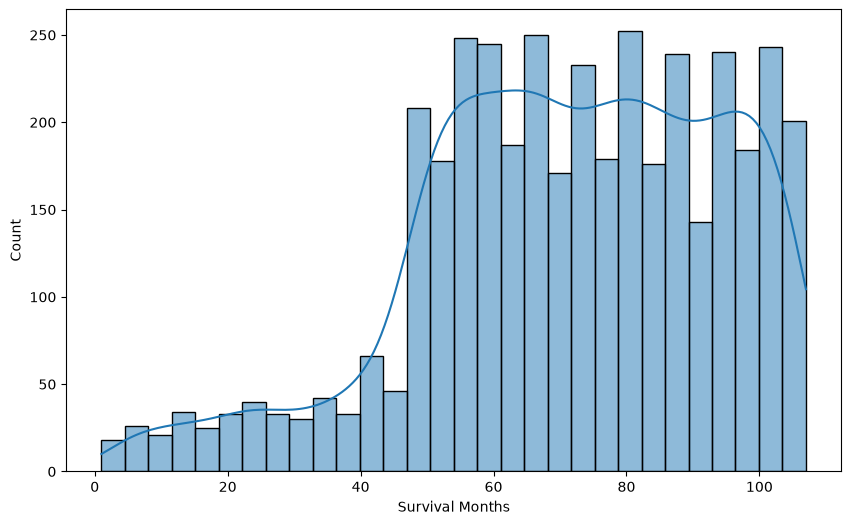

In [ ]:
plt.figure(figsize=(10,6)) # Con este gráfico no solo se muestra la supervivencia en meses, la línea de kde muestra el histograma como si fuese una línea contínua

sns.histplot(df['Survival Months'],bins=30,kde=True)
plt.show()

Ahora vamos a visualizar si hay outliers

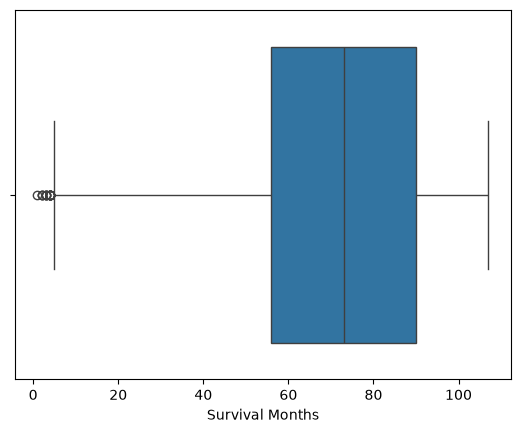

In [3]:
sns.boxplot(x=df['Survival Months'])
plt.show()

Podemos ver que hay unos pocos valores que serían outliers, de los pacientes que sobreviven muy poco, tal y como hemos visto anteriormente.

Ahora pasamos a analizar las siguientes variables relacionadas con la supervivencia:
- T Stage
- N Stage
- 6th Stage
- Grade
- Age
- Tumor Size
- Reginol Node Positive

In [5]:
df.head()

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [6]:
# Análisis univariante de Age

df['Age'].describe()

count    4024.000000
mean       53.972167
std         8.963134
min        30.000000
25%        47.000000
50%        54.000000
75%        61.000000
max        69.000000
Name: Age, dtype: float64

In [9]:
print("Media", df['Age'].mean())
print("Mediana", df['Age'].median())
print("Moda", df['Age'].mode())
print("Asimetría", df['Age'].skew()) 
print("Curtosis", df['Age'].kurtosis())

Media 53.97216699801193
Mediana 54.0
Moda 0    46
Name: Age, dtype: int64
Asimetría -0.2203727859678868
Curtosis -0.7550875306304676


La media y la mediana para la edad se podrían decir que son iguales (53.97 frente 54.0), por lo que indica una distribución equilibrada y sin sesgos.

El valor más repetido es 46 años.

El valor de asimetría es -0.22 lo que indica que la distribución es prácticamente simétrica.

El valor de curtosis -0.75 nos indica que es una distribución más plana de lo normal en el centro, y con menos valores extremos de los esperados.